**Write the names of all group members (max. 5 members)**:
- Weifeng, Ding
- Shangeeth, Poobalasingam

When submitting your work, please follow closely the template below.

Implement the models from scratch using PyTorch (you may adapt `demo.ipynb`) or TensorFlow. Do not use third-party repositories containing ready-made deep hedging implementations. One submission per team is enough.

Make sure all requested results are visible in the executed notebook. A concise **Project Report** is required at the end of the notebook.

# Exercise 1

### Question 1.a

Use Itô’s formula to check that $S_t=s_0\exp(\sigma W_t-\frac12\sigma^2t)$ solves the Black–Scholes SDE with $r=0$. 

**Answer.** With $r=0$ the SDE (1) is $dS_t=\sigma S_t\,dW_t$. Define $f(t,w)=s_0\exp\left(\sigma w-\frac12\sigma^2 t\right)$, so that $S_t=f(t,W_t)$. The derivatives are

$$\frac{\partial f}{\partial t}=-\frac12\sigma^2 f,\qquad \frac{\partial f}{\partial w}=\sigma f,\qquad \frac{\partial^2 f}{\partial w^2}=\sigma^2 f .$$

Itô's formula for a function of Brownian motion gives

$$dS_t=df(t,W_t)=\left(\frac{\partial f}{\partial t}+\frac12\frac{\partial^2 f}{\partial w^2}\right)dt+\frac{\partial f}{\partial w}\,dW_t
=\left(-\frac12\sigma^2 S_t+\frac12\sigma^2 S_t\right)dt+\sigma S_t\,dW_t=\sigma S_t\,dW_t .$$

The initial value is $S_0=f(0,W_0)=f(0,0)=s_0$, so $S_t=s_0\exp(\sigma W_t-\frac12\sigma^2t)$ solves (1) with $r=0$.

### Question 1.b - Generate dataset

(100000, 31) (10000, 31)
mean of S_T (should be about 1): 1.000286828616058
std of log(S_T): 0.17502071325021418  theory: 0.175


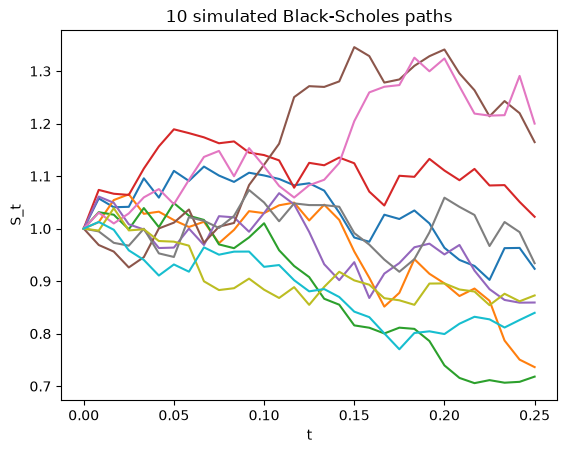

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from scipy.stats import norm, ncx2

np.random.seed(0)
torch.manual_seed(0)

# Generate 100,000 training paths and 10,000 independent test paths.
# Parameters: N=30, s0=1, T=1/4 year, sigma=0.35, r=0.
N = 30
s0 = 1.0
T = 0.25
sigma = 0.35
dt = T / N

# Use the exact geometric Brownian motion update specified in Problem 1(b).
def simulate_bs(m):
    S = np.zeros((m, N + 1))
    S[:, 0] = s0
    for j in range(N):
        Z = np.random.randn(m)
        S[:, j + 1] = S[:, j] * np.exp(-0.5 * sigma**2 * dt + sigma * np.sqrt(dt) * Z)
    return S

# Each path contains N+1=31 prices, including S0 and ST.

# Generate the training set
S_train = simulate_bs(100000)

# Generate the test set
S_test = simulate_bs(10000)

print(S_train.shape, S_test.shape)

# sanity checks: S is a martingale and log(S_T) has std sigma*sqrt(T)
print('mean of S_T (should be about 1):', np.mean(S_train[:, -1]))
print('std of log(S_T):', np.std(np.log(S_train[:, -1])), ' theory:', sigma * np.sqrt(T))

# plot a few paths
for i in range(10):
    plt.plot(np.linspace(0, T, N + 1), S_train[i])
plt.xlabel('t')
plt.ylabel('S_t')
plt.title('10 simulated Black-Scholes paths')
plt.show()

### Question 1.c - Model implementation

In [2]:
# Implement the deep hedging model from scratch.
# You may use and edit the code shown in demo.ipynb.
# Create 30 separate networks H_0,...,H_29, each with its own parameters.
nh = 32  # neurons in the hidden layers

nets = []
for j in range(N):
    net = nn.Sequential(nn.Linear(1, nh),
                        nn.Tanh(),
                        nn.Linear(nh, nh),
                        nn.Tanh(),
                        nn.Linear(nh, 1))
    nets.append(net)

# Each network takes the current stock price as input and returns the shares to hold.
# Do not use future prices as inputs to the trading decision.
def hedge_gains(S):
    # S has shape (batch, N+1), H_j only sees S[:, j]
    gains = torch.zeros(S.shape[0])
    for j in range(N):
        h = nets[j](S[:, j:j+1])[:, 0]
        gains = gains + h * (S[:, j + 1] - S[:, j])
    return gains

### Question 1.d - Model training

Black-Scholes price p = 0.06972591456743071


epoch 0 training loss 0.0004572281613945961


epoch 5 training loss 0.0001543897669762373


epoch 10 training loss 0.00015146555961109698


epoch 15 training loss 0.00013267136819195002


epoch 20 training loss 0.00011943229037569836


epoch 25 training loss 0.00011980543058598414


epoch 30 training loss 0.00011844115942949429


epoch 35 training loss 0.0001183934582513757


epoch 39 training loss 0.00011840883962577209


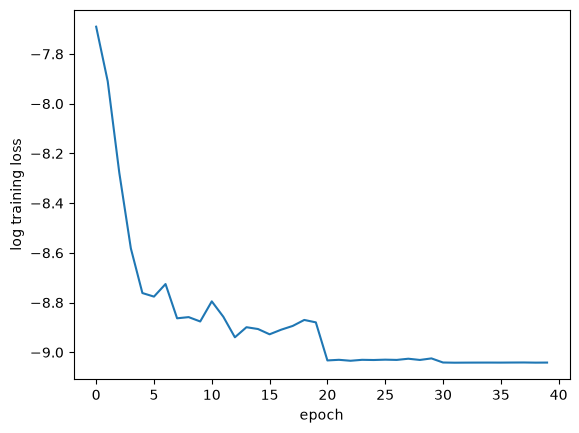

In [3]:
# Implement the call payoff with strike K=1 and maturity T=1/4 year.
K = 1.0

def payoff(ST):
    return torch.clamp(ST - K, min=0)

# Implement the Black-Scholes call-price formula (3).
def bs_call(t, s):
    tau = T - t
    d_plus = (np.log(s / K) + 0.5 * sigma**2 * tau) / (sigma * np.sqrt(tau))
    d_minus = d_plus - sigma * np.sqrt(tau)
    return norm.cdf(d_plus) * s - norm.cdf(d_minus) * K

# Compute and fix the initial premium p=C(0,s0); p is not trained.
p = bs_call(0, s0)
print('Black-Scholes price p =', p)

# Train all 30 networks jointly by minimizing equation (2) on the training set.
S_train_t = torch.tensor(S_train, dtype=torch.float32)
S_test_t = torch.tensor(S_test, dtype=torch.float32)

params = []
for net in nets:
    params = params + list(net.parameters())

n_epochs = 40
batch_size = 1000
optimizer = torch.optim.Adam(params, lr=1e-2)
scheduler = torch.optim.lr_scheduler.MultiStepLR(optimizer, milestones=[20, 30], gamma=0.1)

losses = []
for epoch in range(n_epochs):
    perm = torch.randperm(S_train_t.shape[0])
    for k in range(0, S_train_t.shape[0], batch_size):
        S_batch = S_train_t[perm[k:k + batch_size]]
        error = p + hedge_gains(S_batch) - payoff(S_batch[:, -1])
        loss = torch.mean(error**2)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    scheduler.step()

    # loss on the whole training set
    with torch.no_grad():
        error = p + hedge_gains(S_train_t) - payoff(S_train_t[:, -1])
        losses.append(torch.mean(error**2).item())
    if epoch % 5 == 0 or epoch == n_epochs - 1:
        print('epoch', epoch, 'training loss', losses[-1])

plt.plot(np.log(losses))
plt.xlabel('epoch')
plt.ylabel('log training loss')
plt.show()

### Question 1.e - Model evaluation

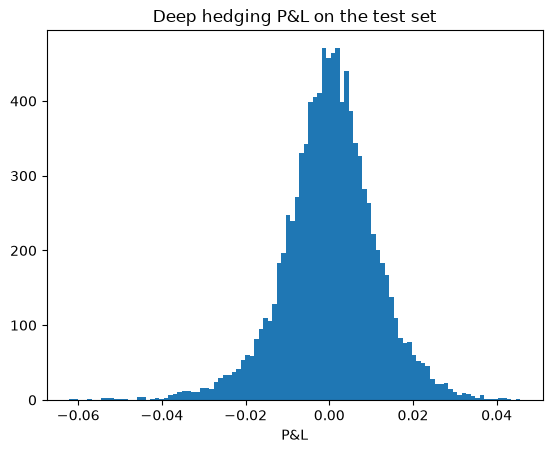

Deep hedge mean: 0.0001590697
Deep hedge std:  0.011112879


In [4]:
# Evaluate the trained hedge on the 10,000 independent test paths.
# Compute P&L = p + sum_j H_j(S_tj)*(S_tj+1-S_tj) - g(ST).
with torch.no_grad():
    pnl_nn = p + hedge_gains(S_test_t) - payoff(S_test_t[:, -1])
pnl_nn = pnl_nn.numpy()

# Plot its histogram and print the empirical mean and standard deviation.
plt.hist(pnl_nn, bins=100)
plt.xlabel('P&L')
plt.title('Deep hedging P&L on the test set')
plt.show()

print('Deep hedge mean:', np.mean(pnl_nn))
print('Deep hedge std: ', np.std(pnl_nn))

### Question 1.f(i) - Compute analytical solution

Show a **step-by-step** derivation of the analytical hedging strategy:

\begin{align*}
H^{\text{BS}}_t(s) & = \frac{\partial C(t, s)}{\partial s} \\
& = \ldots
\end{align*}

No points for solutions without explicit derivation.

**Answer.** Write $\tau=T-t$, $\varphi=\Phi'$ for the standard normal density, and $C(t,s)=\Phi(d_+)s-\Phi(d_-)Ke^{-r\tau}$ with $d_\pm$ as in (3). Since $d_-=d_+-\sigma\sqrt\tau$ does not depend on $s$ beyond $d_+$,

$$\frac{\partial d_+}{\partial s}=\frac{\partial d_-}{\partial s}=\frac{1}{s\sigma\sqrt{\tau}} .$$

By the product and chain rules,

\begin{align*}
H^{\text{BS}}_t(s) & = \frac{\partial C(t, s)}{\partial s} \\
& = \Phi(d_+) + s\,\varphi(d_+)\frac{\partial d_+}{\partial s} - Ke^{-r\tau}\varphi(d_-)\frac{\partial d_-}{\partial s} \\
& = \Phi(d_+) + \frac{1}{s\sigma\sqrt\tau}\Big(s\,\varphi(d_+) - Ke^{-r\tau}\varphi(d_-)\Big).
\end{align*}

The bracket is zero. Using $d_-^2=d_+^2-2d_+\sigma\sqrt\tau+\sigma^2\tau$ and $d_+\sigma\sqrt\tau=\log(s/K)+(r+\frac12\sigma^2)\tau$,

$$\varphi(d_-)=\varphi(d_+)\,e^{d_+\sigma\sqrt\tau-\frac12\sigma^2\tau}=\varphi(d_+)\,e^{\log(s/K)+r\tau}=\varphi(d_+)\frac{s}{K}e^{r\tau},$$

so $Ke^{-r\tau}\varphi(d_-)=s\,\varphi(d_+)$. Therefore

$$H^{\text{BS}}_t(s)=\Phi(d_+)=\Phi\left(\frac{\log(s/K)+(r+\frac12\sigma^2)(T-t)}{\sigma\sqrt{T-t}}\right),$$

which for $r=0$ is $\Phi\left(\frac{\log(s/K)+\frac12\sigma^2(T-t)}{\sigma\sqrt{T-t}}\right)$.

### Question 1.f(ii) - P&L comparison with the analytical hedge

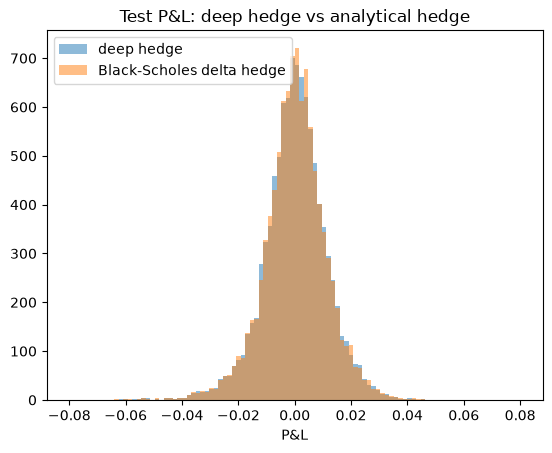

Deep hedge      mean: 0.0001590697  std: 0.011112879
Analytical hedge mean: 0.00016841529518654068  std: 0.01107890368788553
std(deep) / std(analytical) = 1.0030666700856057
standard error of the mean: 0.0001107890368788553


In [5]:
# Implement the formula you found
def bs_delta(t, s):
    tau = T - t
    d_plus = (np.log(s / K) + 0.5 * sigma**2 * tau) / (sigma * np.sqrt(tau))
    return norm.cdf(d_plus)

# Rebalance at t_0,...,t_29 using the same test paths, premium and payoff as in 1.e.
gains_bs = np.zeros(S_test.shape[0])
for j in range(N):
    gains_bs = gains_bs + bs_delta(j * dt, S_test[:, j]) * (S_test[:, j + 1] - S_test[:, j])

# Compute P&L using the same sign convention as in 1.e.
pnl_bs = p + gains_bs - np.maximum(S_test[:, -1] - K, 0)

# Plot histograms of both P&L distributions and print their means and standard deviations.
bins = np.linspace(-0.08, 0.08, 101)
plt.hist(pnl_nn, bins=bins, alpha=0.5, label='deep hedge')
plt.hist(pnl_bs, bins=bins, alpha=0.5, label='Black-Scholes delta hedge')
plt.xlabel('P&L')
plt.legend()
plt.title('Test P&L: deep hedge vs analytical hedge')
plt.show()

print('Deep hedge      mean:', np.mean(pnl_nn), ' std:', np.std(pnl_nn))
print('Analytical hedge mean:', np.mean(pnl_bs), ' std:', np.std(pnl_bs))
print('std(deep) / std(analytical) =', np.std(pnl_nn) / np.std(pnl_bs))
# standard error of the mean, to see if the means are really different from 0
print('standard error of the mean:', np.std(pnl_bs) / np.sqrt(len(pnl_bs)))

How does your deep hedging model compare with the analytical solution? If it's worse, you must improve its performance. A few questions for you to consider...

Have you trained your deep hedging model well?
- Are the losses centered on zero? ($10^{-5} \approx 0$)
- Is their standard deviation comparable with that of the analytical solution?

How can you improve performance?
- train for more epochs
- try a different learning rate
- change the networks' architectures (first try more hidden neurons, then try more hidden layers)
- try different batch sizes
- use a learning rate scheduler (see https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate)
- try a different activation function (e.g. $\tanh$)
- implement regularization (use the `weight_decay` argument in the optimizer)
- implement batch-normalization (see https://pytorch.org/docs/stable/generated/torch.nn.BatchNorm1d.html)
- experiment with different optimizers
- ask in the forum

**Answer.** On the same 10,000 test paths:

| | mean P&L | std P&L |
|---|---|---|
| deep hedge | $1.6\cdot 10^{-4}$ | 0.01111 |
| analytical delta hedge | $1.7\cdot 10^{-4}$ | 0.01108 |

- **Centred on zero:** both means are about $1.5$ standard errors of the mean ($0.011/\sqrt{10^4}\approx 1.1\cdot10^{-4}$), so they are not significantly different from 0. They are also tiny compared with the premium $p\approx 0.0697$. Both hedges see the same test paths, which is why the two means are almost equal.
- **Std:** $\text{std(deep)}/\text{std(analytical)}=1.003$, so the deep hedge is only 0.3% worse than the analytical delta hedge.
- The remaining error of about 0.011 is not a training problem: the analytical hedge has it too, because we only rebalance at $N=30$ dates instead of continuously (it shrinks like $1/\sqrt N$). This is the best the network can do, since it is trained on exactly the same discrete-time loss.

Choices used: 2 hidden layers with 32 neurons and $\tanh$ activation ($\tanh$ is smooth, like the delta we want to learn), Adam with learning rate $10^{-2}$ and batch size 1000, 40 epochs, and a scheduler that divides the learning rate by 10 after epochs 20 and 30.

### Question 1.g - Learned strategy comparison with analytical solution

j = 0  RMSE inside the band: 0.0008  RMSE on [0.5,1.5]: 0.384
j = 10  RMSE inside the band: 0.0049  RMSE on [0.5,1.5]: 0.096
j = 20  RMSE inside the band: 0.0054  RMSE on [0.5,1.5]: 0.0175
j = 29  RMSE inside the band: 0.0044  RMSE on [0.5,1.5]: 0.011


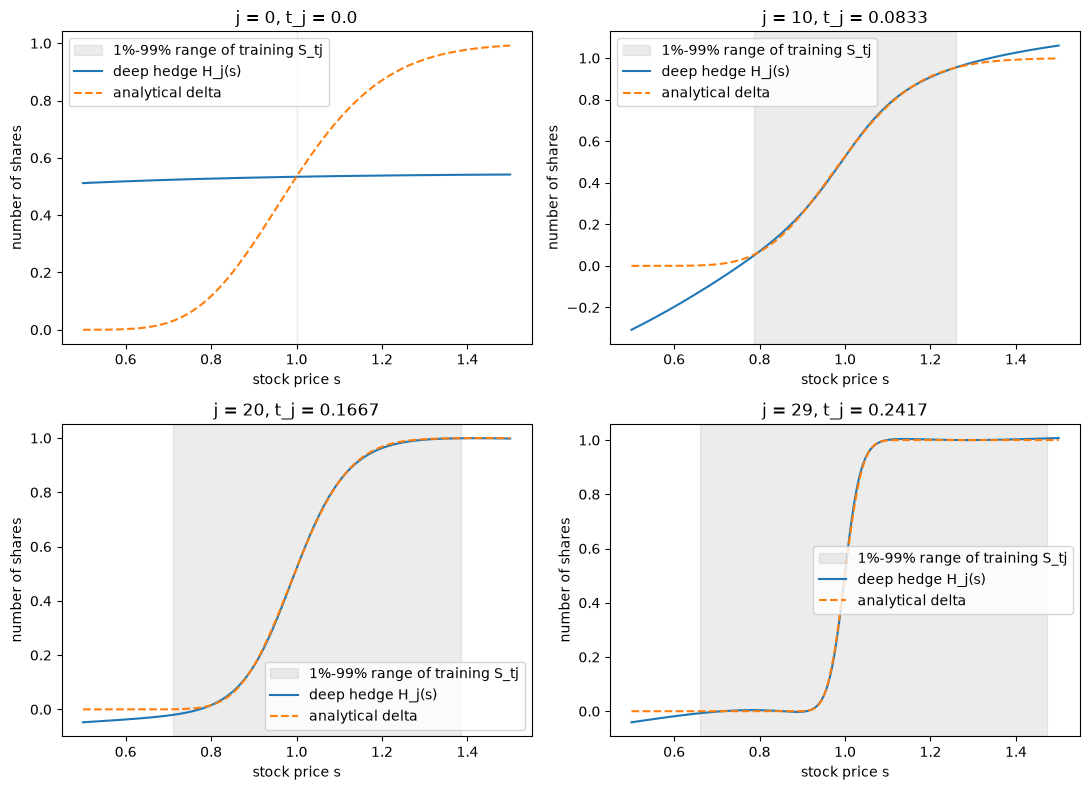

In [6]:
# Compare the hedge functions at j=0,10,20,29.
# Make a grid of stock prices s in [0.5,1.5].
s_grid = np.linspace(0.5, 1.5, 201)
s_grid_t = torch.tensor(s_grid, dtype=torch.float32).reshape(-1, 1)

# Create four plots or panels, one per selected date.
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
axes = axes.flatten()
for k, j in enumerate([0, 10, 20, 29]):
    # In each panel, overlay H_j(s) and the analytical delta evaluated on the same price grid.
    with torch.no_grad():
        h_nn = nets[j](s_grid_t)[:, 0].numpy()
    h_bs = bs_delta(j * dt, s_grid)
    # grey band = where 98% of the training prices S_tj are (1% to 99% quantile)
    lo = np.percentile(S_train[:, j], 1)
    hi = np.percentile(S_train[:, j], 99)
    axes[k].axvspan(lo, hi, color='grey', alpha=0.15, label='1%-99% range of training S_tj')
    axes[k].plot(s_grid, h_nn, label='deep hedge H_j(s)')
    axes[k].plot(s_grid, h_bs, '--', label='analytical delta')
    inside = (s_grid >= lo) & (s_grid <= hi)
    rmse_in = np.sqrt(np.mean((h_nn[inside] - h_bs[inside])**2))
    rmse_all = np.sqrt(np.mean((h_nn - h_bs)**2))
    print('j =', j, ' RMSE inside the band:', round(rmse_in, 4), ' RMSE on [0.5,1.5]:', round(rmse_all, 4))
    # Label the date, both strategies, and axes (stock price and number of shares).
    axes[k].set_title('j = ' + str(j) + ', t_j = ' + str(round(j * dt, 4)))
    axes[k].set_xlabel('stock price s')
    axes[k].set_ylabel('number of shares')
    axes[k].legend()
plt.tight_layout()
plt.show()

- For what times $t_j$ are the two functions most similar? 
- Why?

**Answer.**
- The two functions are most similar at the **later dates $t_{20}$ and $t_{29}$**. On the whole grid $[0.5,1.5]$ the RMSE between $H_j$ and $H^{BS}_{t_j}$ is 0.384, 0.096, 0.018 and 0.011 for $j=0,10,20,29$. Inside the grey band (where 98% of the training prices are), the RMSE is at most 0.005 for every date. At $t_0$ the network is almost flat at about 0.53 and only matches the delta at $s=1$, where $H^{BS}_0(1)=\Phi(d_+)\approx 0.535$. At $t_{10}$ it matches for $s\in[0.8,1.25]$ but goes wrong in the tails (it even goes negative).
- **Why:** the loss (2) is an average over the simulated paths, so $H_j$ is only trained at the prices where $S_{t_j}$ actually lands. At time $t_j$ we have $\log S_{t_j}\sim\mathcal N(-\frac12\sigma^2t_j,\ \sigma^2t_j)$, with standard deviation $\sigma\sqrt{t_j}$ equal to 0, 0.10, 0.14 and 0.17 for $j=0,10,20,29$. At $t_0$ every path starts at $s_0=1$, so only $H_0(1)$ matters and the rest of the curve is never trained. Later the paths are spread over a wider range of prices, so more of $[0.5,1.5]$ is learned. Outside the band the network just extrapolates. One step before maturity the delta is almost a step function at $K$ (its slope at $s=1$ is about $\varphi(0)/(\sigma\sqrt{\Delta t})\approx 12.5$), but the $\tanh$ network still fits it well because there are many training prices near the strike.

# Exercise 2

### Question 2.a - Generate dataset

(100000, 31) (100000, 31) (10000, 31) (10000, 31)
mean of S_T (should be about 1): 0.999036842776015
mean of V_T (should be about b=0.5): 0.5006226623370499  min of V: 0.009404781808205752
risk-neutral price E[g(S_T)] on the test paths: 0.13676164618864892


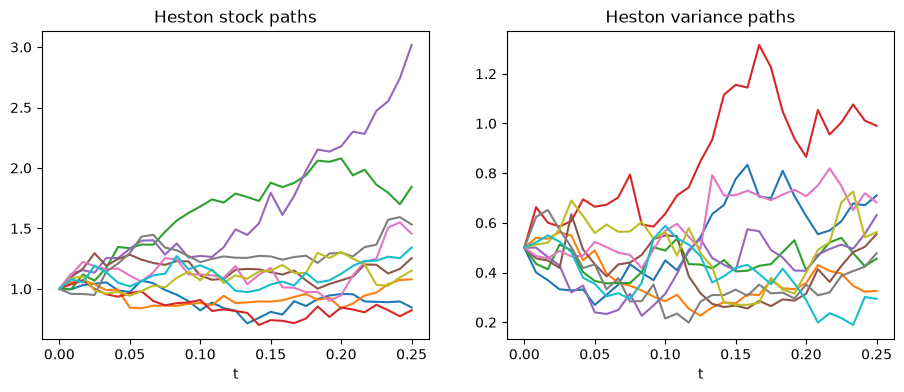

In [7]:
# Generate 100,000 training paths and 10,000 independent test paths of (S,V).
# Parameters: N=30, s0=1, T=1/4 year, rho=-0.3, a=4, b=0.5, v0=0.5, sigma=1.
rho = -0.3
a = 4.0
b = 0.5
v0 = 0.5
sigma_v = 1.0  # called sigma in the Heston model (vol of variance)

# Each stock and variance path contains N+1=31 values.

# (i) Write a function to simulate V using the exact noncentral chi-square transitions.
def simulate_V(m):
    c = sigma_v**2 / (4 * a) * (1 - np.exp(-a * dt))
    df = 4 * a * b / sigma_v**2
    V = np.zeros((m, N + 1))
    V[:, 0] = v0
    for j in range(N):
        nc = np.exp(-a * dt) * V[:, j] / c
        V[:, j + 1] = c * ncx2.rvs(df, nc, size=m)
    return V

# (ii) Write a function to simulate S using the supplied simplified Broadie-Kaya update.
def simulate_S(V):
    m = V.shape[0]
    S = np.zeros((m, N + 1))
    S[:, 0] = s0
    for j in range(N):
        Z = np.random.randn(m)
        S[:, j + 1] = S[:, j] * np.exp(rho / sigma_v * (V[:, j + 1] - V[:, j] - a * b * dt)
                                       + (a * rho / sigma_v - 0.5) * V[:, j] * dt
                                       + np.sqrt((1 - rho**2) * V[:, j] * dt) * Z)
    return S

V_train_h = simulate_V(100000)
S_train_h = simulate_S(V_train_h)
V_test_h = simulate_V(10000)
S_test_h = simulate_S(V_test_h)
print(S_train_h.shape, V_train_h.shape, S_test_h.shape, V_test_h.shape)

# sanity checks: S is a martingale, V goes back to b
print('mean of S_T (should be about 1):', np.mean(S_train_h[:, -1]))
print('mean of V_T (should be about b=0.5):', np.mean(V_train_h[:, -1]), ' min of V:', np.min(V_train_h))
# risk-neutral price E[g(S_T)], used as a reference in 2.d
price_rn = np.mean(np.maximum(S_test_h[:, -1] - K, 0))
print('risk-neutral price E[g(S_T)] on the test paths:', price_rn)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for i in range(10):
    axes[0].plot(np.linspace(0, T, N + 1), S_train_h[i])
    axes[1].plot(np.linspace(0, T, N + 1), V_train_h[i])
axes[0].set_title('Heston stock paths')
axes[1].set_title('Heston variance paths')
axes[0].set_xlabel('t')
axes[1].set_xlabel('t')
plt.show()

### Question 2.b - Model implementation

In [8]:
# Implement the deep hedging model for a generic AVaR level alpha.
# Create 30 separate networks, each taking (current stock price, current variance)
# as input and returning one stock holding.
def make_nets():
    nets_h = []
    for j in range(N):
        net = nn.Sequential(nn.Linear(2, nh),
                            nn.Tanh(),
                            nn.Linear(nh, nh),
                            nn.Tanh(),
                            nn.Linear(nh, 1))
        nets_h.append(net)
    return nets_h

# loss X = g(S_T) - sum_j H_j(S_tj, V_tj) * (S_tj+1 - S_tj)
def hedging_loss(nets_h, S, V):
    gains = torch.zeros(S.shape[0])
    for j in range(N):
        x = torch.stack([S[:, j], V[:, j]], dim=1)
        h = nets_h[j](x)[:, 0]
        gains = gains + h * (S[:, j + 1] - S[:, j])
    return payoff(S[:, -1]) - gains

# Implement the AVaR objective in equation (6), with a trainable scalar threshold w.
def avar_objective(X, w, alpha):
    return w + torch.mean(torch.clamp(X - w, min=0)) / (1 - alpha)

### Question 2.c - Model training

alpha 0.5 epoch 0 training loss 0.17297162115573883 w 0.1365577131509781


alpha 0.5 epoch 5 training loss 0.16338561475276947 w 0.13874167203903198


alpha 0.5 epoch 10 training loss 0.16224922239780426 w 0.13729429244995117


alpha 0.5 epoch 15 training loss 0.16219264268875122 w 0.13432691991329193


alpha 0.5 epoch 20 training loss 0.1601451337337494 w 0.1362479031085968


alpha 0.5 epoch 25 training loss 0.1601400524377823 w 0.13546887040138245


... (8 outputs left out)

alpha 0.9 epoch 25 training loss 0.19167128205299377 w 0.1744680106639862


alpha 0.9 epoch 30 training loss 0.19140048325061798 w 0.17488068342208862


alpha 0.9 epoch 35 training loss 0.19139067828655243 w 0.17501267790794373


alpha 0.9 epoch 39 training loss 0.19137105345726013 w 0.17468678951263428


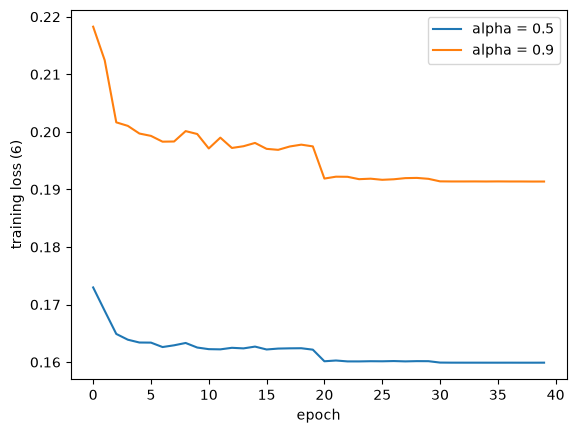

In [9]:
# Train two separate deep hedging models for alpha=0.5 and alpha=0.9.
# Use the call option with strike K=1 and maturity T=1/4 year.
S_train_ht = torch.tensor(S_train_h, dtype=torch.float32)
V_train_ht = torch.tensor(V_train_h, dtype=torch.float32)
S_test_ht = torch.tensor(S_test_h, dtype=torch.float32)
V_test_ht = torch.tensor(V_test_h, dtype=torch.float32)

# Minimize equation (6), jointly optimizing all network parameters and scalar w.
# Each model has its own networks and one threshold w shared across its paths.
# Include w in the optimizer; do not fix a Black-Scholes premium in this objective.
def train_avar(alpha):
    nets_h = make_nets()
    # start w at the alpha-quantile of the payoff (this is the best w when we do not hedge at all)
    w_start = np.quantile(np.maximum(S_train_h[:, -1] - K, 0), alpha)
    w = torch.tensor(float(w_start), requires_grad=True)
    params = [w]
    for net in nets_h:
        params = params + list(net.parameters())
    optimizer = torch.optim.Adam(params, lr=1e-2)
    scheduler = torch.optim.lr_scheduler.MultiStepLR(optimizer, milestones=[20, 30], gamma=0.1)

    losses = []
    for epoch in range(n_epochs):
        perm = torch.randperm(S_train_ht.shape[0])
        for k in range(0, S_train_ht.shape[0], batch_size):
            idx = perm[k:k + batch_size]
            X = hedging_loss(nets_h, S_train_ht[idx], V_train_ht[idx])
            loss = avar_objective(X, w, alpha)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
        scheduler.step()

        with torch.no_grad():
            X = hedging_loss(nets_h, S_train_ht, V_train_ht)
            losses.append(avar_objective(X, w, alpha).item())
        if epoch % 5 == 0 or epoch == n_epochs - 1:
            print('alpha', alpha, 'epoch', epoch, 'training loss', losses[-1], 'w', w.item())
    return nets_h, w, losses

nets_05, w_05, losses_05 = train_avar(0.5)
nets_09, w_09, losses_09 = train_avar(0.9)

plt.plot(losses_05, label='alpha = 0.5')
plt.plot(losses_09, label='alpha = 0.9')
plt.xlabel('epoch')
plt.ylabel('training loss (6)')
plt.legend()
plt.show()

### Question 2.d - Price comparison

In [10]:
# Freeze each trained model and its threshold w.
# Evaluate equation (6) on the same 10,000 test paths to estimate each price p.
with torch.no_grad():
    X_test_05 = hedging_loss(nets_05, S_test_ht, V_test_ht)
    X_test_09 = hedging_loss(nets_09, S_test_ht, V_test_ht)
    p_05 = avar_objective(X_test_05, w_05, 0.5).item()
    p_09 = avar_objective(X_test_09, w_09, 0.9).item()

# Print p for alpha=0.5 and alpha=0.9.
print('p for alpha = 0.5:', p_05, '  (w =', w_05.item(), ')')
print('p for alpha = 0.9:', p_09, '  (w =', w_09.item(), ')')
print('reference: risk-neutral price E[g(S_T)] =', price_rn)

# Explain which price is higher and why.
# -> see the answer below

p for alpha = 0.5: 0.15976592898368835   (w = 0.13550549745559692 )
p for alpha = 0.9: 0.19112807512283325   (w = 0.17468678951263428 )
reference: risk-neutral price E[g(S_T)] = 0.13676164618864892


**Answer.** On the test set we get $p_{0.5}\approx 0.160$ and $p_{0.9}\approx 0.191$, so **the price for $\alpha=0.9$ is higher**.

$\mathrm{AVaR}_\alpha(X)=\frac{1}{1-\alpha}\int_\alpha^1 q_u(X)\,du$ is the average of the worst $(1-\alpha)$ part of the losses. For $\alpha=0.5$ we average the worst 50% of the losses, and for $\alpha=0.9$ only the worst 10%, which are larger. Since quantiles grow with $u$, $\mathrm{AVaR}_{0.9}(X)\ge \mathrm{AVaR}_{0.5}(X)$ for every strategy $H$, so the infimum over $H$ is also larger. In other words, $\alpha=0.9$ is a more risk-averse seller who wants to be covered against the more extreme losses, and so charges a higher premium.

Both prices are above the risk-neutral price $\mathbb E[g(S_T)]\approx 0.137$. Under $\mathbb Q$ the trading gains have mean 0 and $\mathrm{AVaR}_\alpha(X)\ge\mathbb E[X]$, so $p_\alpha\ge\mathbb E[g(S_T)]$. The difference (0.023 for $\alpha=0.5$, 0.054 for $\alpha=0.9$) is a risk premium for the volatility risk that cannot be hedged with the stock, because the Heston model is incomplete.

### Question 2.e - P&L comparison

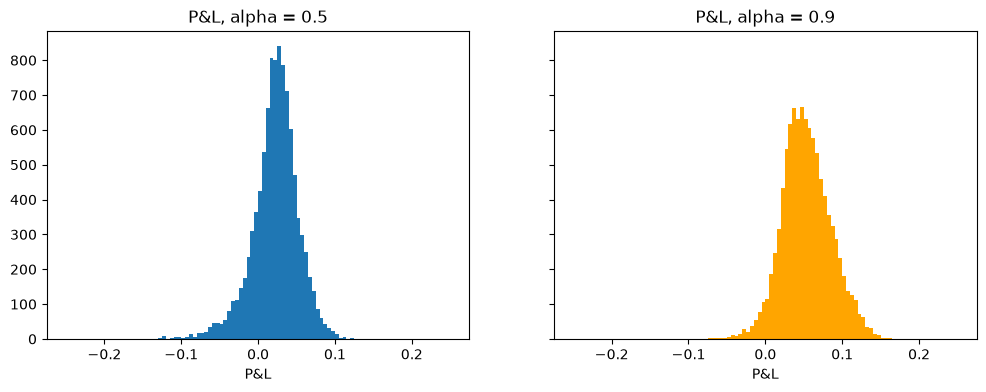

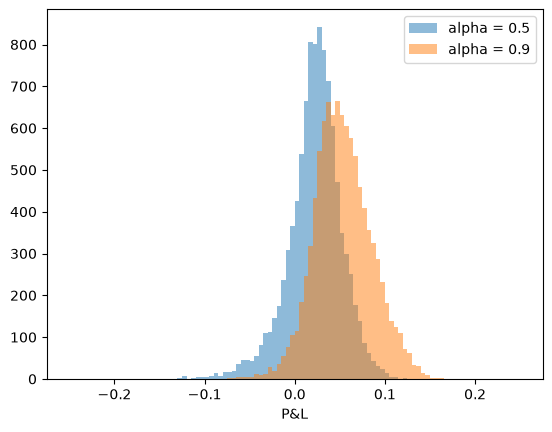

alpha = 0.5: mean 0.022232885  std 0.029947368
alpha = 0.9: mean 0.053555414  std 0.031640086
alpha = 0.5: P(P&L < 0) = 0.1867   5% quantile of P&L = -0.031122163
alpha = 0.9: P(P&L < 0) = 0.0378   5% quantile of P&L = 0.005379749


In [11]:
# Compute test P&L for alpha=0.5 and alpha=0.9.
# Use the same test paths for both models.
# P&L = p + sum_j H_j * (S_tj+1 - S_tj) - g(S_T) = p - X
pnl_05 = p_05 - X_test_05.numpy()
pnl_09 = p_09 - X_test_09.numpy()

# Plot both P&L histograms with comparable axes and binning.
bins = np.linspace(-0.25, 0.25, 101)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True, sharey=True)
axes[0].hist(pnl_05, bins=bins)
axes[0].set_title('P&L, alpha = 0.5')
axes[1].hist(pnl_09, bins=bins, color='orange')
axes[1].set_title('P&L, alpha = 0.9')
axes[0].set_xlabel('P&L')
axes[1].set_xlabel('P&L')
plt.show()

plt.hist(pnl_05, bins=bins, alpha=0.5, label='alpha = 0.5')
plt.hist(pnl_09, bins=bins, alpha=0.5, label='alpha = 0.9')
plt.xlabel('P&L')
plt.legend()
plt.show()

# Print the empirical mean and standard deviation for each distribution.
print('alpha = 0.5: mean', np.mean(pnl_05), ' std', np.std(pnl_05))
print('alpha = 0.9: mean', np.mean(pnl_09), ' std', np.std(pnl_09))

# how often do we lose money, and how bad is the 5% worst case?
print('alpha = 0.5: P(P&L < 0) =', np.mean(pnl_05 < 0), '  5% quantile of P&L =', np.quantile(pnl_05, 0.05))
print('alpha = 0.9: P(P&L < 0) =', np.mean(pnl_09 < 0), '  5% quantile of P&L =', np.quantile(pnl_09, 0.05))

**Answer.**

| | mean P&L | std P&L | $P(\text{P\&L}<0)$ | 5% quantile of P&L |
|---|---|---|---|---|
| $\alpha=0.5$ | 0.022 | 0.030 | 18.7% | $-0.031$ |
| $\alpha=0.9$ | 0.054 | 0.032 | 3.8% | $+0.005$ |

- **Mean:** the P&L is $p_\alpha - X$, and both models have about the same mean loss $\mathbb E[X]\approx 0.137$. So the difference in mean P&L comes from the premium: $\alpha=0.9$ charges about 0.031 more and makes about 0.031 more on average.
- **Std:** the standard deviations are similar, and slightly larger for $\alpha=0.9$. Both strategies hedge most of the risk in the same way (holding about delta shares), and neither minimizes the variance; they only care about the tail of the losses.
- **Tail:** this is the main difference. Since AVaR is cash invariant, $\mathrm{AVaR}_\alpha(-\mathrm{P\&L})=\mathrm{AVaR}_\alpha(X)-p_\alpha=0$ on the test set. With $\alpha=0.5$ the worst 50% of outcomes break even on average, so the seller still loses money on 18.7% of the paths. With $\alpha=0.9$ even the worst 10% break even on average, so the histogram is shifted to the right, only 3.8% of the paths lose money, and the 5% quantile is positive.
- The P&L is never exactly zero, unlike in Black–Scholes, because the variance risk cannot be hedged with the stock alone.

## Project Report

Provide a concise synthesis of your findings across both problems. Refer to the results above and focus on the main conclusions.

### Approach

Briefly describe how you simulated the paths, trained the hedges, and evaluated them on the test sets.

We simulated 100,000 training paths and 10,000 independent test paths with $N=30$ trading dates and $T=1/4$ in both models. For Black–Scholes ($\sigma=0.35$, $r=0$, $s_0=1$) we used the exact log-normal update. For Heston ($\rho=-0.3$, $a=4$, $b=v_0=0.5$, vol of variance 1) we first drew the variance exactly from its non-central $\chi^2$ transition (`scipy.stats.ncx2`) and then the stock with the simplified Broadie–Kaya step. Simple sanity checks confirm the simulation: $\mathbb E[S_T]\approx 1$ (martingale), $\mathrm{std}(\log S_T)\approx \sigma\sqrt T = 0.175$, and $\mathbb E[V_T]\approx b$.

The hedge is made of 30 separate networks $H_0,\dots,H_{29}$, one per trading date. Each has 2 hidden layers of 32 $\tanh$ neurons and only sees what is known at $t_j$: $S_{t_j}$ in Problem 1 and $(S_{t_j},V_{t_j})$ in Problem 2. All networks are trained together with Adam (learning rate $10^{-2}$, batch size 1000, 40 epochs, learning rate divided by 10 after epochs 20 and 30).
- In Problem 1 we minimized the squared hedging error (2) with the fixed Black–Scholes premium $p=C(0,s_0)\approx 0.0697$.
- In Problem 2 we minimized the AVaR loss (6) over the networks and a trainable scalar $w$, with one model for $\alpha=0.5$ and one for $\alpha=0.9$. We started $w$ at the $\alpha$-quantile of the payoff, which is the best $w$ when we do not hedge at all.

Nothing was tuned on the test paths. After training, the models were frozen and evaluated once on the test set: P&L histograms, means and standard deviations, and for Heston the value of (6) on the test set as the price $p_\alpha$. We also compared the learned holdings with the analytical delta $\Phi(d_+)$ at $j=0,10,20,29$.

### Key results

Summarize the comparison between the learned hedge and Black–Scholes delta. For Heston, report the two estimated premiums and the main differences in test P&L.

- Black–Scholes premium: $p = C(0,s_0) = 0.0697$.
- The deep hedge P&L is centred on zero (mean $1.6\cdot10^{-4}$, about 1.5 standard errors), and its std is 0.01111 against 0.01108 for the analytical delta hedge (ratio 1.003).
- Learned holdings vs. delta, RMSE on $[0.5,1.5]$: 0.384, 0.096, 0.018 and 0.011 for $j=0,10,20,29$. Inside the range where the training prices are, the RMSE is at most 0.005 at all four dates.
- Heston AVaR prices: $p_{0.5}=0.160$ and $p_{0.9}=0.191$, against a risk-neutral price $\mathbb E[g(S_T)]=0.137$.
- Test P&L on the same 10,000 paths:

| Model | premium | P&L mean | P&L std | $P(\text{P\&L}<0)$ | 5% quantile |
|---|---|---|---|---|---|
| BS: deep hedge | 0.0697 | 0.0002 | 0.0111 | – | – |
| BS: analytical delta | 0.0697 | 0.0002 | 0.0111 | – | – |
| Heston: AVaR $\alpha=0.5$ | 0.160 | 0.022 | 0.030 | 18.7% | $-0.031$ |
| Heston: AVaR $\alpha=0.9$ | 0.191 | 0.054 | 0.032 | 3.8% | $+0.005$ |

### Interpretation

Explain how closely the learned holdings matched delta at the selected dates and how the AVaR level affected the premium and the P&L distribution.

In the complete Black–Scholes market, deep hedging learns the right strategy without being told the formula. Where there is data, the learned holdings lie on top of $\Phi(d_+)$, and the P&L is as good as with the analytical delta. The remaining error of about 0.011 is not a training problem: it comes from rebalancing only 30 times, and the analytical hedge has it too. The match with the delta gets better with time because the networks only learn where the simulated prices are. At $t_0$ every path starts at $s_0=1$, so only $H_0(1)\approx 0.535$ is learned and the rest of the curve is extrapolation. At later dates the prices are spread over a wider range (std of $\log S_{t_j}$ from 0.10 at $j=10$ to 0.17 at $j=29$), so more of $[0.5,1.5]$ is learned. Even the almost step-shaped delta just before maturity is fitted well. The mismatch outside the data range does not hurt the P&L, because those prices almost never happen.

In the incomplete Heston market a perfect hedge is not possible, so the price depends on how much risk the seller accepts. AVaR increases with $\alpha$: with $\alpha=0.9$ the seller wants to be covered on average in the worst 10% of the outcomes, not only in the worst 50%. This is why $p_{0.9}>p_{0.5}$. Both prices are above the risk-neutral price, and the difference is a risk premium for the volatility risk that cannot be hedged with the stock. A higher premium mostly shifts the P&L distribution to the right: the std stays about the same, but the share of paths with a loss falls from 18.7% to 3.8%, and the 5% worst case becomes a small profit.

### Robustness

Discuss how simulation noise and random network initialization could affect your conclusions. No additional experiments are required.

The test-set noise is small compared to the effects we look at. With 10,000 test paths, the standard error of a mean P&L is about 1% of its std ($\approx 1.1\cdot 10^{-4}$ in Problem 1), so the Black–Scholes means cannot be told apart from 0. A std is only known to about $1/\sqrt{2n}\approx 0.7\%$, so the 0.3% gap between the deep hedge and the delta hedge is within noise. The AVaR price for $\alpha=0.9$ is the noisiest number, because only about 1,000 test paths are in the tail. Since all hedges are evaluated on the same test paths, comparing them is more reliable than each number on its own.

The training also has random parts: the network initialization, the order of the minibatches, and a non-convex loss. With another seed the networks, prices and stds would change a little. The least determined parts are $H_0$ (it only ever sees $s=1$) and the tails of the price grid. The main conclusions should hold for any seed, because the effects are large: $p_{0.9}>p_{0.5}>\mathbb E[g(S_T)]$, a Black–Scholes P&L centred near zero with a std close to the delta hedge, and the match with the delta where data exist. Small differences, like the gap between the two Heston stds, should not be over-interpreted.

### Limitations

Discuss the main limitations, such as discrete rebalancing and reliance on simulated markets.

- We only rebalance at 30 dates, so even the exact delta hedge leaves an error (std about 0.011, which shrinks like $1/\sqrt N$).
- All data is simulated from the same model that we hedge in, with known parameters, under $\mathbb Q$ and with $r=0$. Good test results say nothing about real data, wrong model parameters, jumps or the real-world drift.
- There are no transaction costs, bid–ask spreads or position limits. In practice these are the main reasons to use deep hedging instead of the delta.
- In Heston we assume that the variance $V_t$ can be observed, but in practice it has to be estimated. It also cannot be traded, so the market stays incomplete. The price depends on the chosen risk measure and $\alpha$.
- We used one network size and one set of hyperparameters, and studied only one option (a 3-month at-the-money call).